# EMBER2024: Dataset Tour & Exploratory Data Analysis

---

This notebook was written with the aim of reproducing key statistics and visualisations from the EMBER2024 paper, including dataset composition, label distribution, family size analysis and the "emerging families" number from Section 4.4.

In [1]:
# Importing all the required libraries for data manipulation, visualisation and dataset loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from thrember import read_metadata  
import polars as pl
import json

## Load JSONL Metadata

In [ ]:
# Please enter directory here containing EMBER2024 JSONL files
JSONL_DIR = Path(r"")

# Extracting JSON metadata via thember
train_df, test_df, challenge_df = read_metadata(JSONL_DIR)

print(f"Train: {len(train_df):,}, Test: {len(test_df):,}, Challenge: {len(challenge_df):,}")

Train: 2,626,000, Test: 606,000, Challenge: 6,315


In [3]:
# We add a split column to know which set each row belongs to before concatenation
train_df = train_df.with_columns(pl.lit('train').alias('split'))
test_df = test_df.with_columns(pl.lit('test').alias('split'))
challenge_df = challenge_df.with_columns(pl.lit('challenge').alias('split'))

# Combine all three datasets into one large DataFrame
all_df = pl.concat([train_df, test_df, challenge_df])

print(f"Total rows: {len(all_df):,}")

Total rows: 3,238,315


In [4]:
print("Label Distribution by Split:")

# Group the data by split and label, then count the files in each group
label_dist = (
    all_df.group_by(['split', 'label'])
    .agg(pl.len().alias('count'))
    .with_columns(
        (pl.col('count') / pl.col('count').sum().over('split') * 100)
        .round(2).alias('percent')
    )
    .sort(['split', 'label'])
)

# Display resulting table
print(label_dist)

Label Distribution by Split:
shape: (5, 4)
┌───────────┬───────┬─────────┬─────────┐
│ split     ┆ label ┆ count   ┆ percent │
│ ---       ┆ ---   ┆ ---     ┆ ---     │
│ str       ┆ i64   ┆ u32     ┆ f64     │
╞═══════════╪═══════╪═════════╪═════════╡
│ challenge ┆ 1     ┆ 6315    ┆ 100.0   │
│ test      ┆ 0     ┆ 303000  ┆ 50.0    │
│ test      ┆ 1     ┆ 303000  ┆ 50.0    │
│ train     ┆ 0     ┆ 1313000 ┆ 50.0    │
│ train     ┆ 1     ┆ 1313000 ┆ 50.0    │
└───────────┴───────┴─────────┴─────────┘


### File Type Distribution by Split

Files span 6 formats: Win32, Win64, .NET, APK, ELF and PDF. The code below groups by split and file_type, reproducing Table 3 from EMBER2024.

In [5]:
print("File Type Counts:")

# Group the data by split and file type, then count the files in each group
file_type_counts = (
    all_df.group_by(['split', 'file_type'])
    .agg(pl.len().alias('count'))
    .pivot(values='count', index='split', on='file_type', aggregate_function='sum')
    .fill_null(0) # Fill any missing combinations with 0
)

print(file_type_counts)

File Type Counts:
shape: (3, 7)
┌───────────┬────────┬─────────┬───────┬─────────┬────────┬───────┐
│ split     ┆ APK    ┆ Win32   ┆ ELF   ┆ Dot_Net ┆ Win64  ┆ PDF   │
│ ---       ┆ ---    ┆ ---     ┆ ---   ┆ ---     ┆ ---    ┆ ---   │
│ str       ┆ u32    ┆ u32     ┆ u32   ┆ u32     ┆ u32    ┆ u32   │
╞═══════════╪════════╪═════════╪═══════╪═════════╪════════╪═══════╡
│ train     ┆ 208000 ┆ 1560000 ┆ 26000 ┆ 260000  ┆ 520000 ┆ 52000 │
│ challenge ┆ 256    ┆ 3225    ┆ 386   ┆ 829     ┆ 814    ┆ 805   │
│ test      ┆ 48000  ┆ 360000  ┆ 6000  ┆ 60000   ┆ 120000 ┆ 12000 │
└───────────┴────────┴─────────┴───────┴─────────┴────────┴───────┘


### Tag Coverage on Malicious Files

The code below extracts malicious samples only, then counts how many have family labels and various tags. The aim is reproducing 
83.9% family label coverage number and and Table 4.

In [6]:
# Combine the training and test malicious samples (label == 1)
malicious_all = pl.concat([train_df, test_df]).filter(pl.col('label') == 1)
total_malicious = len(malicious_all)

# This function is used to to check if a column is empty or null
def empty_or_null(col):
    return (pl.col(col).is_null()) | (pl.col(col).list.len() == 0)

# Obtain the total malicious and number of tagged/labelled files per column
stats = malicious_all.select(
    pl.len().alias("total_malicious"),

    # For family label count non-null family assignments
    (pl.col('family').is_not_null().sum()).alias("family_labeled"),

    # Count files where column is not empty or null
    (~empty_or_null('behavior')).sum().alias("behavior_tagged"),
    (~empty_or_null('packer')).sum().alias("packer_tagged"),
    (~empty_or_null('exploit')).sum().alias("exploit_tagged"),
    (~empty_or_null('group')).sum().alias("group_tagged"),
    (~empty_or_null('file_property')).sum().alias("file_property_tagged")
).with_columns([

    # Convert counted numbers to percentages
    (pl.col("family_labeled") * 100.0 / total_malicious).round(1).alias("family %"),
    (pl.col("behavior_tagged") * 100.0 / total_malicious).round(1).alias("behavior %"),
    (pl.col("packer_tagged") * 100.0 / total_malicious).round(1).alias("packer %"),
    (pl.col("exploit_tagged") * 100.0 / total_malicious).round(1).alias("exploit %"),
    (pl.col("group_tagged") * 100.0 / total_malicious).round(1).alias("group %"),
    (pl.col("file_property_tagged") * 100.0 / total_malicious).round(1).alias("file_property %")
])

print(stats.to_pandas().to_string(index=False))

 total_malicious  family_labeled  behavior_tagged  packer_tagged  exploit_tagged  group_tagged  file_property_tagged  family %  behavior %  packer %  exploit %  group %  file_property %
         1616000         1349959           735505          99221            2983         16170                142263      83.5        45.5       6.1        0.2      1.0              8.8


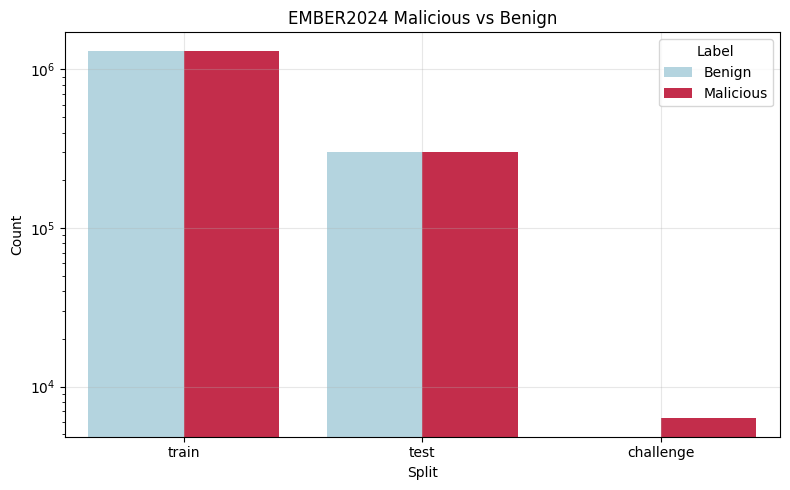

In [7]:
# Plotting the label balance
plt.figure(figsize=(8,5))
sns.countplot(data=all_df.to_pandas(), x='split', hue='label', palette={0:'lightblue', 1:'crimson'})

# Adding title and axis labels
plt.title('EMBER2024 Malicious vs Benign')
plt.xlabel('Split')
plt.ylabel('Count')

# Using logarithmic scale and adding grid lines 
plt.yscale('log')
plt.legend(title='Label', labels=['Benign', 'Malicious'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('label_balance_by_split.png', dpi=300)
plt.show()

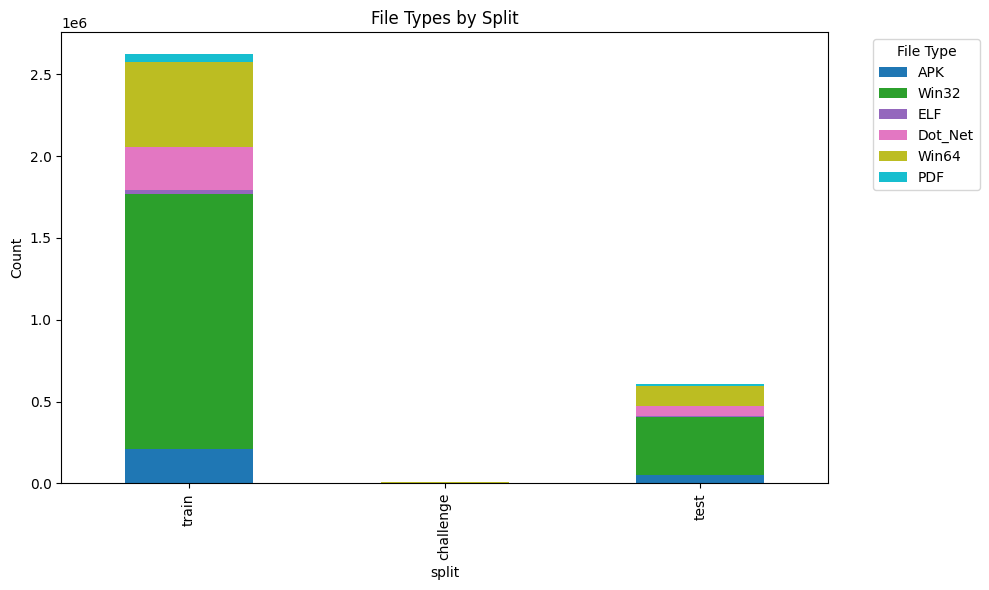

In [8]:
# Convert data frame to pandas and make use of split column to create stacked bar chart
file_type_counts.to_pandas().set_index('split').plot(
    kind='bar', stacked=True, figsize=(10,6), colormap='tab10'
)

# Adding title and axis labels
plt.title('File Types by Split')
plt.ylabel('Count')


plt.legend(title='File Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('table_3_file_type_distribution.png', dpi=300)
plt.show()

### Family Size Zipfian Distribution

The code below extracts samples per family, bins them and plots a histogram. The aim is reproducing Figure 2 from EMBER2024, confirming that family sizes follow a zipfian distribution.

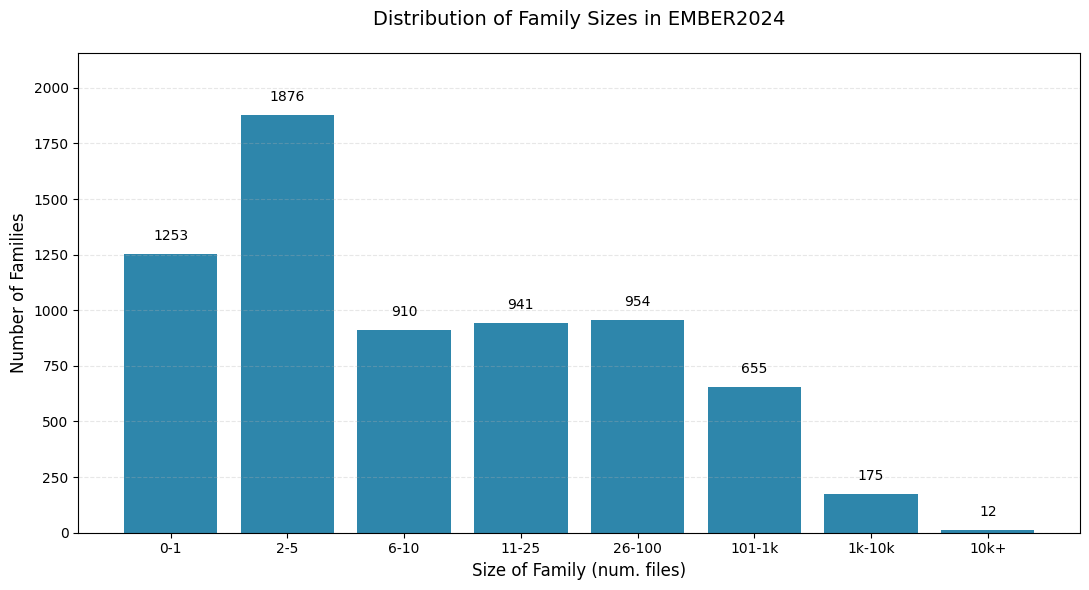

In [9]:
# Extract the number of samples per family from labeled malicious files
family_sizes = (
    malicious_all
    .filter(pl.col('family').is_not_null()) # Keep only files with known family label
    .group_by('family')  # Group by family
    .agg(pl.len().alias('size'))  # Extract sizes in descending order 
    .sort('size', descending=True)['size']
    .to_numpy()
)

bins = [1, 2, 6, 11, 26, 101, 1001, 10001, np.inf]  # Define bins for grouping family sizes 
labels = ['0-1', '2-5', '6-10', '11-25', '26-100', '101-1k', '1k-10k', '10k+']

# Counting how many families fall into each bin
counts, _ = np.histogram(family_sizes, bins=bins)

# Creating figure
plt.figure(figsize=(11, 6))
bars = plt.bar(labels, counts, color='#2E86AB')

# Adding the value labels on top of each bar 
for bar in bars:
    height = bar.get_height()
    if height > 0:
        # Place label at 50 pixels above the bar
        plt.text(bar.get_x() + bar.get_width()/2., height + 50, f'{int(height)}', ha='center', va='bottom', fontsize=10)

# Formatting the plot with labels and title
plt.title('Distribution of Family Sizes in EMBER2024', fontsize=14, pad=20)
plt.xlabel('Size of Family (num. files)', fontsize=12)
plt.ylabel('Number of Families', fontsize=12)

# Adding some headroom above tallest bar for labels
plt.ylim(0, max(counts) * 1.15)
  
# Adding grid lines and adjsuting layout
plt.grid(True, axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

plt.savefig('fig_2_zipfian_family_sizes.png', dpi=300, bbox_inches='tight')
plt.show()

### Top 10 Families and Tags

The code below extracts the 10 most frequent values for families, behaviors, packers, file properties, exploits and threat groups. The aim is reproducing Appendix B from EMBER2024.

In [10]:
# Extracting the top 10 malware families
top_families = (
    malicious_all
    .filter(pl.col('family').is_not_null()) # Exclude all unlabelled files
    .group_by('family')
    .agg(pl.len().alias('size'))
    .sort('size', descending=True)
    .head(10)
)
print("Top 10 Families:")
print(top_families)
print()

# Extracting the top 10 behaviors
top_behaviors = (
    malicious_all
    .explode('behavior')
    .filter(pl.col('behavior').is_not_null())
    .group_by('behavior')
    .agg(pl.len().alias('size'))
    .sort('size', descending=True)
    .head(10)
)
print("Top 10 Behaviors:")
print(top_behaviors)
print()

# Extracting the top 10 packers
top_packers = (
    malicious_all
    .explode('packer')
    .filter(pl.col('packer').is_not_null())
    .group_by('packer')
    .agg(pl.len().alias('size'))
    .sort('size', descending=True)
    .head(10)
)
print("Top 10 Packers:")
print(top_packers)
print()

# Extracting the top 10 file properties
top_fileprops = (
    malicious_all
    .explode('file_property')
    .filter(pl.col('file_property').is_not_null())
    .group_by('file_property')
    .agg(pl.len().alias('size'))
    .sort('size', descending=True)
    .head(10)
)
print("Top 10 File Properties:")
print(top_fileprops)
print()

# Extracting the top 10 exploited vulnerabilities
top_vulns = (
    malicious_all
    .explode('exploit')
    .filter(pl.col('exploit').is_not_null())
    .group_by('exploit')
    .agg(pl.len().alias('size'))
    .sort('size', descending=True)
    .head(10)
)
print("Top 10 Exploited Vulns:")
print(top_vulns)
print()

# Extracting the top 10 threat groups
top_groups = (
    malicious_all
    .explode('group')
    .filter(pl.col('group').is_not_null())
    .group_by('group')
    .agg(pl.len().alias('size'))
    .sort('size', descending=True)
    .head(10)
)
print("Top 10 Threat Groups:")
print(top_groups)
print()

Top 10 Families:
shape: (10, 2)
┌─────────────┬────────┐
│ family      ┆ size   │
│ ---         ┆ ---    │
│ str         ┆ u32    │
╞═════════════╪════════╡
│ berbew      ┆ 174479 │
│ wacatac     ┆ 81478  │
│ expiro      ┆ 74338  │
│ cosmu       ┆ 53965  │
│ xmrig       ┆ 28903  │
│ upatre      ┆ 25296  │
│ sfone       ┆ 22177  │
│ glupteba    ┆ 21670  │
│ grandoreiro ┆ 20551  │
│ flystudio   ┆ 18141  │
└─────────────┴────────┘

Top 10 Behaviors:
shape: (10, 2)
┌────────────┬────────┐
│ behavior   ┆ size   │
│ ---        ┆ ---    │
│ str        ┆ u32    │
╞════════════╪════════╡
│ backdoor   ┆ 228349 │
│ virus      ┆ 121971 │
│ worm       ┆ 76115  │
│ downloader ┆ 61523  │
│ spyware    ┆ 55780  │
│ coinminer  ┆ 37680  │
│ dropper    ┆ 33291  │
│ adware     ┆ 24867  │
│ phishing   ┆ 21782  │
│ ransom     ┆ 16279  │
└────────────┴────────┘

Top 10 Packers:
shape: (10, 2)
┌─────────────────┬───────┐
│ packer          ┆ size  │
│ ---             ┆ ---   │
│ str             ┆ u32   │
╞═════

### Newly Emerging Families 

The code below aims to verify the below claim from Section 4.4 of EMBER2024:

*EMBER2024 has 2,709 files from 75 families that appear 10 or more times in the test set but are not in the training set.*

In [11]:
# Extract all the malicious samples from the train and test splits
train_mal = train_df.filter(pl.col('label') == 1)
test_mal  = test_df.filter(pl.col('label') == 1)

print(f"Malicious in train: {len(train_mal):,}")
print(f"Malicious in test : {len(test_mal):,}")

# Extract all the families that appear in training set (keep only files with non-null family labels)
train_with_family = train_mal.filter(pl.col('family').is_not_null())
train_families = set(train_with_family.select('family').to_series().to_list())

print(f"Total number of unique families in training set: {len(train_families):,}")
print()

# Filter the test set to labeled  malicious files with family only
test_with_family = test_mal.filter(pl.col('family').is_not_null())

# Exclude all the families that appears in the training set
test_families_only = test_with_family.filter(~pl.col('family').is_in(list(train_families)))

print(f"Families in test set that are completely missing from train: {test_families_only['family'].n_unique()}")
print(f"Samples from these families: {len(test_families_only):,}")
print()

# Group by family, count the no. of test samples per family and keep only families with 10 ore more samples
emerging_families = (
    test_families_only
    .group_by('family')
    .agg(pl.len().alias('test_size'))
    .filter(pl.col('test_size') >= 10)
    .sort('test_size', descending=True)  # Sort in descending order to show largest emerging families first
)

num_emerging_families = len(emerging_families)
num_emerging_samples  = emerging_families['test_size'].sum()

print(f"Number of emerging families greater or equal than 10 samples in test, 0 in train: {num_emerging_families}")
print(f"Total samples from these families: {num_emerging_samples:,}")
print()
print("Top 10 emerging families:")
print(emerging_families.head(10))

Malicious in train: 1,313,000
Malicious in test : 303,000
Total number of unique families in training set: 6,363

Families in test set that are completely missing from train: 413
Samples from these families: 1,155

Number of emerging families greater or equal than 10 samples in test, 0 in train: 9
Total samples from these families: 522

Top 10 emerging families:
shape: (9, 2)
┌───────────────────┬───────────┐
│ family            ┆ test_size │
│ ---               ┆ ---       │
│ str               ┆ u32       │
╞═══════════════════╪═══════════╡
│ etset             ┆ 223       │
│ yomal             ┆ 82        │
│ birich            ┆ 57        │
│ suschil           ┆ 52        │
│ ramses            ┆ 48        │
│ credentialflusher ┆ 17        │
│ edrstealer        ┆ 16        │
│ gregcent          ┆ 15        │
│ lednur            ┆ 12        │
└───────────────────┴───────────┘


## Load .dat Feature Vectors for Model Training

The code in this section loads numerical feature vectors from memory-mapped .dat files. These shall be used for model training, unlike the JSONL metadata above which was for data analysis.

The code below memory maps feature matrices and labels from .dat files. This allows for the handling of large files without loading into RAM.

In [ ]:
# Please enter directory here containing EMBER2024 .dat feature files
DATA_DIR = Path(r"")
print(f"Dataset: {DATA_DIR}")

# This function loads the feature matrix and binary labels for a given dataset split.
def load_xy(subset):

    # Build the paths to the .dat files (where features are stored in the root and labels in Malicious-benign subfolder)
    X_path = DATA_DIR / f"X_{subset}.dat"
    y_path = DATA_DIR / "Malicious-benign" / f"y_{subset}.dat"

    # Validate that both files actaully exist before attempting to load either one
    if not X_path.exists():
        raise FileNotFoundError(f"Missing {X_path}")
    if not y_path.exists():
        raise FileNotFoundError(f"Missing {y_path}")
    
    # Memory map features and labels
    X = np.memmap(X_path, dtype=np.float32, mode='r').reshape(-1, 2568)
    y = np.memmap(y_path, dtype=np.int32, mode='r')
    return X, y

# Load the dataset splits (train, test, challenge)
X_train, y_train = load_xy("train")
X_test,  y_test  = load_xy("test")
X_chal,  y_chal  = load_xy("challenge")

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"X_chal:  {X_chal.shape}")
print(f"Features: {X_train.shape[1]}")

Dataset: <local EMBER2024 data directory>
X_train: (2626000, 2568)
X_test:  (606000, 2568)
X_chal:  (6315, 2568)
Features: 2568


The code below counts benign and malicious samples from arrays, to confirm that .dat labels match JSONL metadata:

In [13]:
# This function calculates and prints number of benign and malicious samples
def print_balance(y, name):
    benign = (y==0).sum()
    malicious = (y==1).sum()
    total = len(y)
    print(f"{name}: {benign:,} benign, {malicious:,} malicious, {malicious/total:.1%} malware")

# Display label balance for all splits
print_balance(y_train, "Train")
print_balance(y_test,  "Test")
print_balance(y_chal,  "Challenge")

Train: 1,313,000 benign, 1,313,000 malicious, 50.0% malware
Test: 303,000 benign, 303,000 malicious, 50.0% malware
Challenge: 0 benign, 6,315 malicious, 100.0% malware


The code below loads all label categories from the .dat files. The printed output reproduces the # Total Tags column from Table 4 from EMBER2024.

In [14]:
# Defining all the possible label categories available in EMBER2024
LABEL_CATEGORIES = [
    "Malicious-benign", 
    "family", 
    "behaviour", 
    "file_property", 
    "packer", 
    "exploit", 
    "group"
]

# Minimum samples required for a class (change between 1 and 10)
CLASS_MIN = 1 

# Expected sample counts per split verified above
SPLIT_SIZES = {
    "train": 2_626_000,
    "test": 606_000,
    "challenge": 6_315
}

# This function builds the folder path for a particular label category
def get_category_path(category, class_min):
    if category == "Malicious-benign":
        return DATA_DIR / "Malicious-benign"
     # Assumes that multi-label categories are stored in for e.g. "behaviour class min=1"
    return DATA_DIR / f"{category} class min={class_min}"


# This function loads the label array for a category and split.
def load_labels(category, subset, class_min=1):

    # Build full file path
    path = get_category_path(category, class_min) / f"y_{subset}.dat"

    # Skip missing files
    if not path.exists():
        print(f"Missing: {path}")
        return None, None, None
    
    # Memory map the integer array
    y_raw = np.memmap(path, dtype=np.int32, mode='r')

    # Get expected number of samples for this split 
    n_samples = SPLIT_SIZES[subset]

    # Determine the format based on whether 1D or 2D
    # If file contains exactly one integer per sample then it is multi-class case
    if len(y_raw) == n_samples:
        y = y_raw.copy()
        is_multilabel = False
    # If file contains n_samples × n_tags then it is multi-label binary matrix case
    elif len(y_raw) % n_samples == 0:
        # Calculating the number of tags in this category
        n_tags = len(y_raw) // n_samples
        # Reshape the flat array into 2D matrix
        y = y_raw.reshape(n_samples, n_tags)
        is_multilabel = True
    # In cases of data corruption or version mismatch    
    else:
        raise ValueError(f"Irregular shape for {category}/{subset}: {len(y_raw)}")
    
    return y

# Binary labels
y_train_binary = load_labels("Malicious-benign", "train")
y_test_binary = load_labels("Malicious-benign", "test")
y_chal_binary = load_labels("Malicious-benign", "challenge")

# Family labels
y_train_family = load_labels("family", "train")
y_test_family = load_labels("family", "test")

# Multi-label tags:
y_train_behaviour = load_labels("behaviour", "train")
y_test_behaviour = load_labels("behaviour", "test")
y_train_fileprop = load_labels("file_property", "train")
y_test_fileprop = load_labels("file_property", "test")
y_train_packer = load_labels("packer", "train")
y_test_packer = load_labels("packer", "test")
y_train_exploit = load_labels("exploit", "train")
y_test_exploit = load_labels("exploit", "test")
y_train_group = load_labels("group", "train")
y_test_group = load_labels("group", "test")

# Print loaded data
print(f"Behavior: Train={y_train_behaviour.shape[1]}, Test={y_test_behaviour.shape[1]}")
print(f"File property:  Train={y_train_fileprop.shape[1]}, Test={y_test_fileprop.shape[1]}")
print(f"Packer: Train={y_train_packer.shape[1]}, Test={y_test_packer.shape[1]}")
print(f"Exploited vuln.: Train={y_train_exploit.shape[1]}, Test={y_test_exploit.shape[1]}")
print(f"Threat group: Train={y_train_group.shape[1]}, Test={y_test_group.shape[1]} ")

Behavior: Train=117, Test=125
File property:  Train=29, Test=30
Packer: Train=51, Test=52
Exploited vuln.: Train=263, Test=293
Threat group: Train=40, Test=43 
